In [198]:
import pandas as pd
import numpy as np

In [199]:
df_charging = pd.read_csv(r"D:\Aswini\EDA\EV_charging\evcharging\Data\ChargingRecords.csv")

In [200]:
# Quick dataset overview
print("=== Shape ===")
print(df_charging.shape) #to identify the number of rows columns

print("\n=== Column Names ===")
print(df_charging.columns) #To get the column names

print("\n=== First 5 Rows ===")
print(df_charging.head()) #First 5 rows will be displayed

print("\n=== Info ===")
print(df_charging.info()) #The datatypes of each column will be obtained


=== Shape ===
(72856, 13)

=== Column Names ===
Index(['UserID', 'ChargerID', 'ChargerCompany', 'Location', 'ChargerType',
       'StartDay', 'StartTime', 'EndDay', 'EndTime', 'StartDatetime',
       'EndDatetime', 'Duration', 'Demand'],
      dtype='str')

=== First 5 Rows ===
   UserID  ChargerID  ChargerCompany Location  ChargerType    StartDay  \
0       0          1               1    hotel            0  2022-09-15   
1       0          1               1    hotel            0  2022-09-14   
2       0          1               1    hotel            0  2022-09-14   
3       0          1               1    hotel            0  2022-09-29   
4       0          1               1    hotel            0  2022-09-25   

  StartTime      EndDay   EndTime     StartDatetime       EndDatetime  \
0  20:54:02  2022-09-15  23:59:13  2022-09-15 20:54  2022-09-15 23:59   
1  20:01:05  2022-09-14  21:31:04  2022-09-14 20:01  2022-09-14 21:31   
2  18:54:30  2022-09-14  19:54:29  2022-09-14 18:54  2022

In [201]:
#Analysing the dataset for missing values, duplicated rows and incorrect column datatypes
print(f" === Missing values ===\n{df_charging.isnull().sum()}\n")
print(f" === Duplicated Rows ===\n{df_charging.duplicated().sum()}\n")
print(f" === Datatypes of columns ===\n{df_charging.dtypes}")

 === Missing values ===
UserID            0
ChargerID         0
ChargerCompany    0
Location          0
ChargerType       0
StartDay          0
StartTime         0
EndDay            0
EndTime           0
StartDatetime     0
EndDatetime       0
Duration          0
Demand            0
dtype: int64

 === Duplicated Rows ===
13

 === Datatypes of columns ===
UserID              int64
ChargerID           int64
ChargerCompany      int64
Location              str
ChargerType         int64
StartDay              str
StartTime             str
EndDay                str
EndTime               str
StartDatetime         str
EndDatetime           str
Duration            int64
Demand            float64
dtype: object


### 📊 Data Quality Check
1. **No missing values** → dataset is complete.  
2. **Duplicated rows** → 13 duplicates need removal.  
3. **Incorrect datatypes** →  
   - Dates/times stored as strings (`StartDay`, `StartTime`, `EndDay`, `EndTime`, `StartDatetime`, `EndDatetime`).  
   - Categorical fields stored as integers or strings (`Location`, `ChargerCompany`, `ChargerType`).  


### DATA CLEANING

In [ ]:
# Converting categorical columns
df_charging['Location'] = df_charging['Location'].astype('category')
df_charging['ChargerCompany'] = df_charging['ChargerCompany'].astype('category')
df_charging['ChargerType'] = df_charging['ChargerType'].astype('category')

# Droping duplicates
df_cleaned = df_charging.drop_duplicates()

# Converting dates and times
df_cleaned['StartDay'] = pd.to_datetime(df_cleaned['StartDay'], format="%Y-%m-%d").dt.date
df_cleaned['EndDay']   = pd.to_datetime(df_cleaned['EndDay'], format="%Y-%m-%d").dt.date
df_cleaned['StartTime'] = pd.to_datetime(df_cleaned['StartTime'], format="%H:%M:%S").dt.time
df_cleaned['EndTime']   = pd.to_datetime(df_cleaned['EndTime'], format="%H:%M:%S").dt.time

# Full datetime conversion
df_cleaned['StartDatetime'] = pd.to_datetime(df_cleaned['StartDatetime'], format="%Y-%m-%d %H:%M")
df_cleaned['EndDatetime']   = pd.to_datetime(df_cleaned['EndDatetime'], format="%Y-%m-%d %H:%M")

# Calculating duration from StartDay+StartTime and EndDay+EndTime
start = pd.to_datetime(df_cleaned['StartDay'].astype(str) + ' ' + df_cleaned['StartTime'].astype(str))
end   = pd.to_datetime(df_cleaned['EndDay'].astype(str)   + ' ' + df_cleaned['EndTime'].astype(str))

df_cleaned['Duration_seconds'] = (end - start).dt.total_seconds().astype(int)
df_cleaned['Duration_minutes'] = np.floor(df_cleaned['Duration_seconds'] / 60 + 0.5).astype(int)

# Droping invalid durations (negative or zero)
df_cleaned = df_cleaned[(df_cleaned['Duration_seconds'] > 0) & (df_cleaned['Duration'] > 0)].reset_index(drop=True)

# Final shape and datatypes
print("Cleaned dataset shape:", df_cleaned.shape)
print("Cleaned dataset datatypes:", df_cleaned.dtypes)


Cleaned dataset shape: (72105, 15)
Cleaned dataset datatypes: UserID                       int64
ChargerID                    int64
ChargerCompany            category
Location                  category
ChargerType               category
StartDay                    object
StartTime                   object
EndDay                      object
EndTime                     object
StartDatetime       datetime64[us]
EndDatetime         datetime64[us]
Duration                     int64
Demand                     float64
Duration_seconds             int64
Duration_minutes             int64
dtype: object


### 🧹 Data Cleaning & Transformation Pipeline

1. **Categorical Conversion** : Converted `Location`, `ChargerCompany`, and `ChargerType` to `category` dtype.
2. **Duplicate Removal** : Dropped 13 duplicated rows.
3. **Date & Time Conversion**
   - Converted `StartDay` and `EndDay` → `datetime.date`.
   - Converted `StartTime` and `EndTime` → `datetime.time`.
   - Converted `StartDatetime` and `EndDatetime` → `datetime64`.
4. **Duration Calculation**: Calculated `Duration_seconds` and `Duration_minutes`.
 5. **Invalid Duration Filtering** : Dropped sessions with negative or zero durations.



# 📊 Exploratory Data Analysis (EDA)

In [203]:
import seaborn as sns
import matplotlib.pyplot as plt

In [204]:
# Summary of numeric columns
print(df_cleaned.describe())

# Summary of categorical columns
print(df_cleaned.describe(include='category'))

             UserID     ChargerID               StartDatetime  \
count  72105.000000  72105.000000                       72105   
mean     336.877692    525.895111  2022-04-19 17:57:16.981901   
min        0.000000      1.000000         2021-09-30 17:14:00   
25%        0.000000    107.000000         2022-01-26 09:48:00   
50%       61.000000    301.000000         2022-04-27 19:03:00   
75%      405.000000    738.000000         2022-07-17 14:05:00   
max     2501.000000   2671.000000         2022-09-30 23:11:00   
std      551.833888    569.897201                         NaN   

                      EndDatetime      Duration        Demand  \
count                       72105  72105.000000  72105.000000   
mean   2022-04-19 20:34:02.374038    152.727717     17.571774   
min           2021-10-01 00:07:00      1.000000      0.010000   
25%           2022-01-26 11:44:00     41.000000      7.700000   
50%           2022-04-27 21:29:00    114.000000     14.260000   
75%           2022-07-17

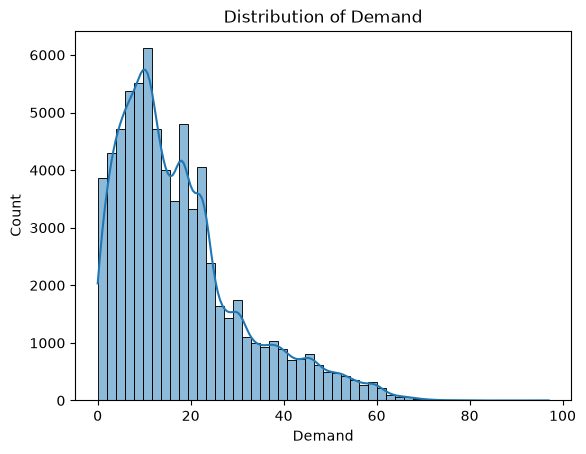

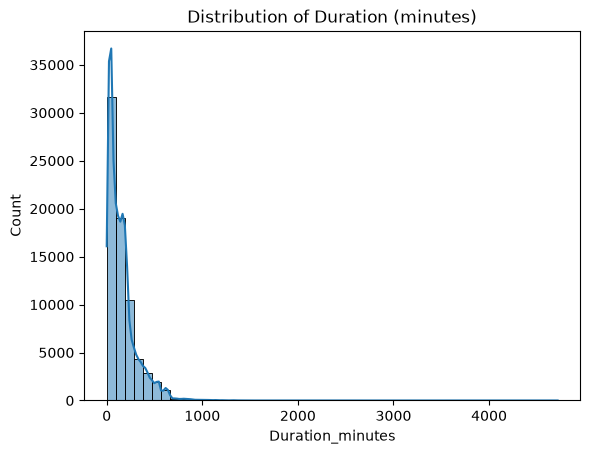

In [205]:
# Demand distribution
sns.histplot(df_cleaned['Demand'], bins=50, kde=True)
plt.title("Distribution of Demand")
plt.show()

# Duration distribution
sns.histplot(df_cleaned['Duration_minutes'], bins=50, kde=True)
plt.title("Distribution of Duration (minutes)")
plt.show()


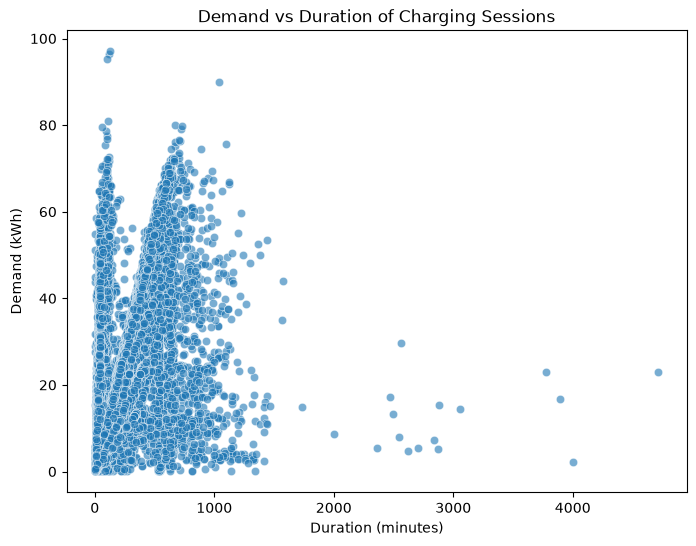

In [206]:
# Scatter plot of Demand vs Duration
plt.figure(figsize=(8,6))
sns.scatterplot(x=df_cleaned['Duration_minutes'], y=df_cleaned['Demand'], alpha=0.6)

plt.xlabel("Duration (minutes)")
plt.ylabel("Demand (kWh)")
plt.title("Demand vs Duration of Charging Sessions")
plt.show()


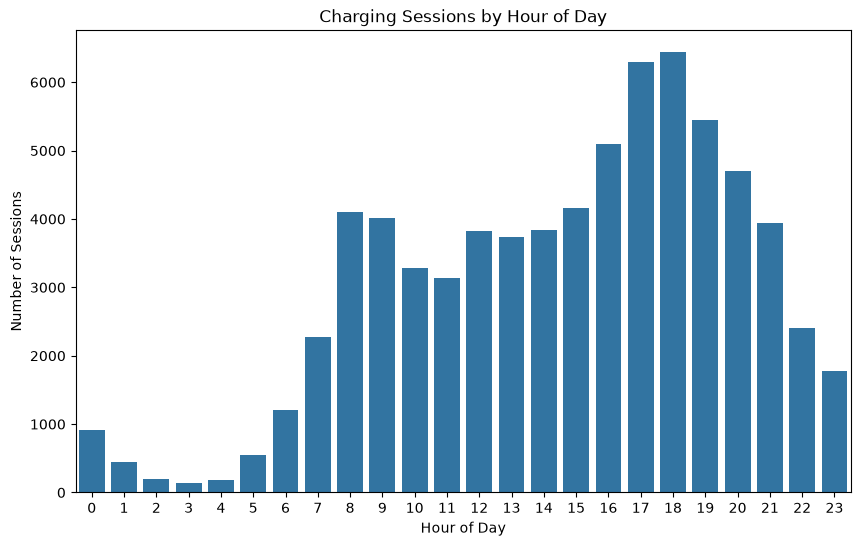

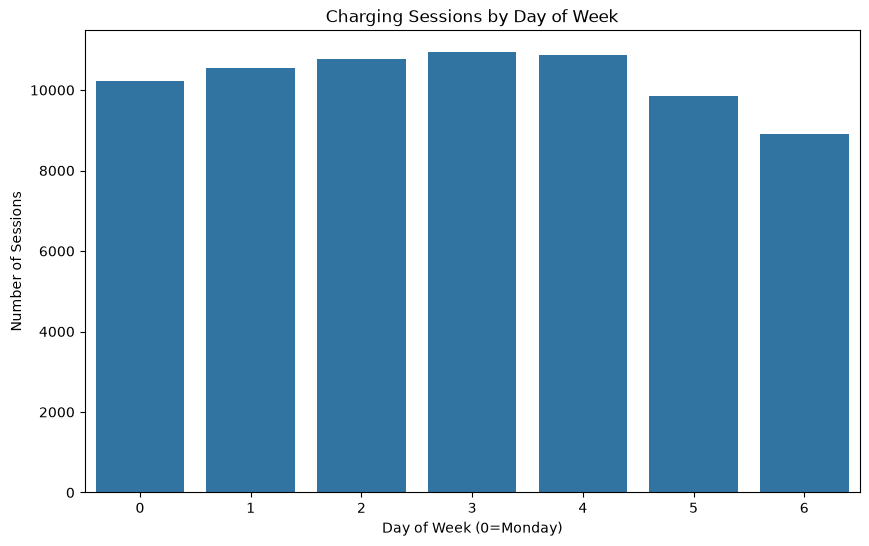

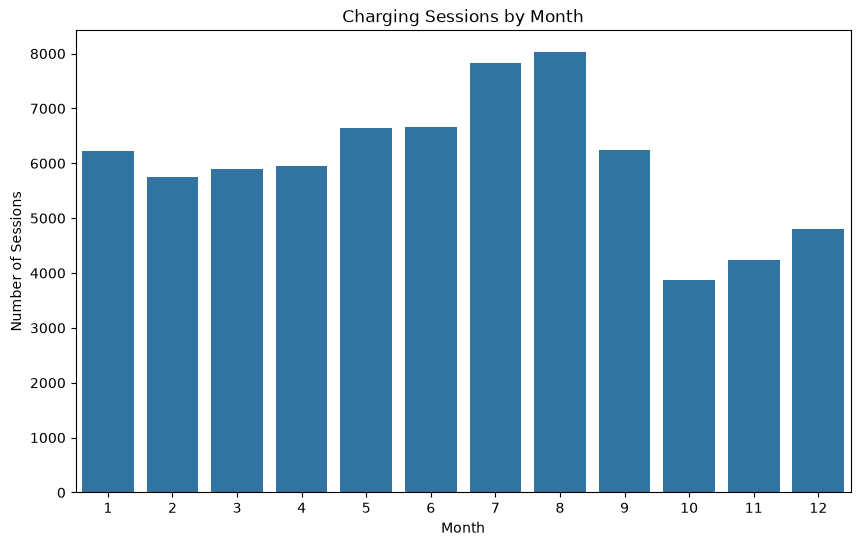

In [207]:
#Charging sessions by Hour of the day
plt.figure(figsize=(10,6))
sns.countplot(x=df_cleaned['StartDatetime'].dt.hour)
plt.xlabel("Hour of Day")
plt.ylabel("Number of Sessions")
plt.title("Charging Sessions by Hour of Day")
plt.show()

#Charging Sessions by Day of Week
plt.figure(figsize=(10,6))
sns.countplot(x=df_cleaned['StartDatetime'].dt.dayofweek)
plt.xlabel("Day of Week (0=Monday)")
plt.ylabel("Number of Sessions")
plt.title("Charging Sessions by Day of Week")
plt.show()

#Charging Sessions by Month
plt.figure(figsize=(10,6))
sns.countplot(x=df_cleaned['StartDatetime'].dt.month)
plt.xlabel("Month")
plt.ylabel("Number of Sessions")
plt.title("Charging Sessions by Month")
plt.show()

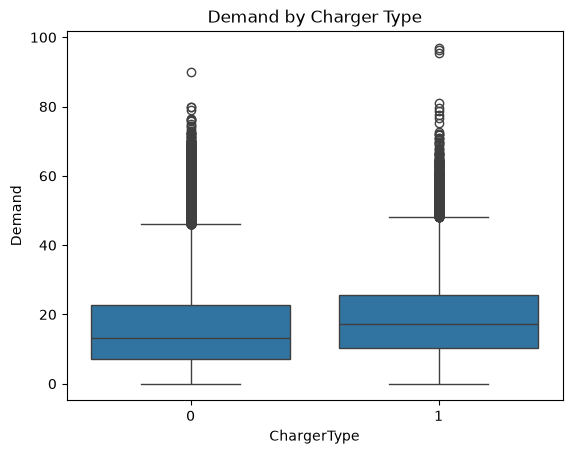

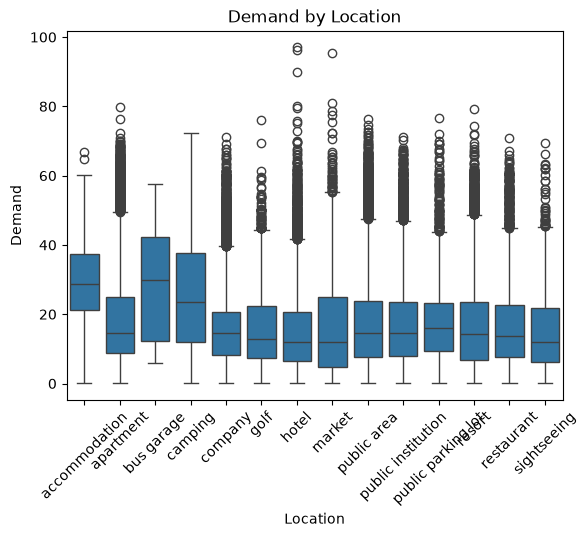

In [208]:
# Demand by ChargerType
sns.boxplot(x='ChargerType', y='Demand', data=df_cleaned)
plt.title("Demand by Charger Type")
plt.show()

# Demand by Location
sns.boxplot(x='Location', y='Demand', data=df_cleaned)
plt.xticks(rotation=45)
plt.title("Demand by Location")
plt.show()


C:\Users\aswin\AppData\Local\Temp\ipykernel_19416\2033240914.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_chargers.index, x=top_chargers.values, orient='h', palette="viridis", ax=axes[0])
C:\Users\aswin\AppData\Local\Temp\ipykernel_19416\2033240914.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=avg_demand.index, x=avg_demand.values, orient='h', palette="magma", ax=axes[1])


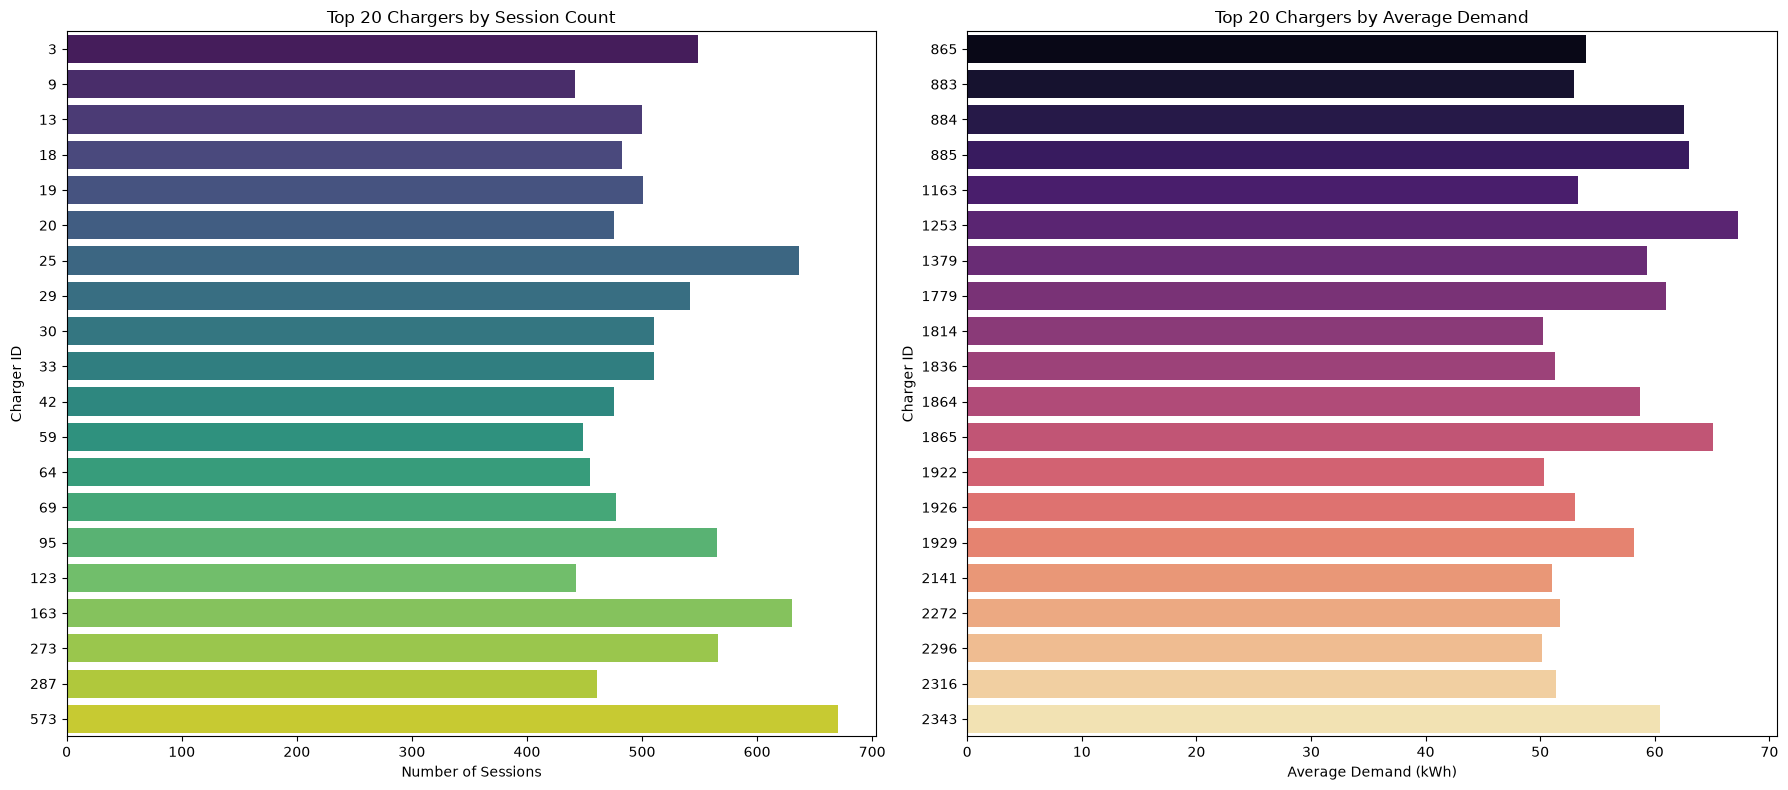

In [209]:
import matplotlib.pyplot as plt
import seaborn as sns

# Top 20 chargers by session count
top_chargers = df_cleaned['ChargerID'].value_counts().head(20)

# Top 20 chargers by average demand
avg_demand = df_cleaned.groupby('ChargerID')['Demand'].mean().sort_values(ascending=False).head(20)

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(18,8))

# Plot sessions per charger
sns.barplot(y=top_chargers.index, x=top_chargers.values, orient='h', palette="viridis", ax=axes[0])
axes[0].set_xlabel("Number of Sessions")
axes[0].set_ylabel("Charger ID")
axes[0].set_title("Top 20 Chargers by Session Count")

# Plot average demand per charger
sns.barplot(y=avg_demand.index, x=avg_demand.values, orient='h', palette="magma", ax=axes[1])
axes[1].set_xlabel("Average Demand (kWh)")
axes[1].set_ylabel("Charger ID")
axes[1].set_title("Top 20 Chargers by Average Demand")

plt.tight_layout()
plt.show()


In [210]:
import pandas as pd

# Select only numeric columns
numeric_df = df_cleaned.select_dtypes(include=['int64','float64'])

# Compute correlation
corr_matrix = numeric_df.corr(method='pearson')  # or 'spearman' for categorical encodings
print(corr_matrix)


                    UserID  ChargerID  Duration    Demand  Duration_seconds  \
UserID            1.000000   0.384965 -0.065633  0.005818         -0.073528   
ChargerID         0.384965   1.000000 -0.145599 -0.019052         -0.147960   
Duration         -0.065633  -0.145599  1.000000  0.654899          0.925773   
Demand            0.005818  -0.019052  0.654899  1.000000          0.600224   
Duration_seconds -0.073528  -0.147960  0.925773  0.600224          1.000000   
Duration_minutes -0.073533  -0.147990  0.925772  0.600211          0.999998   

                  Duration_minutes  
UserID                   -0.073533  
ChargerID                -0.147990  
Duration                  0.925772  
Demand                    0.600211  
Duration_seconds          0.999998  
Duration_minutes          1.000000  


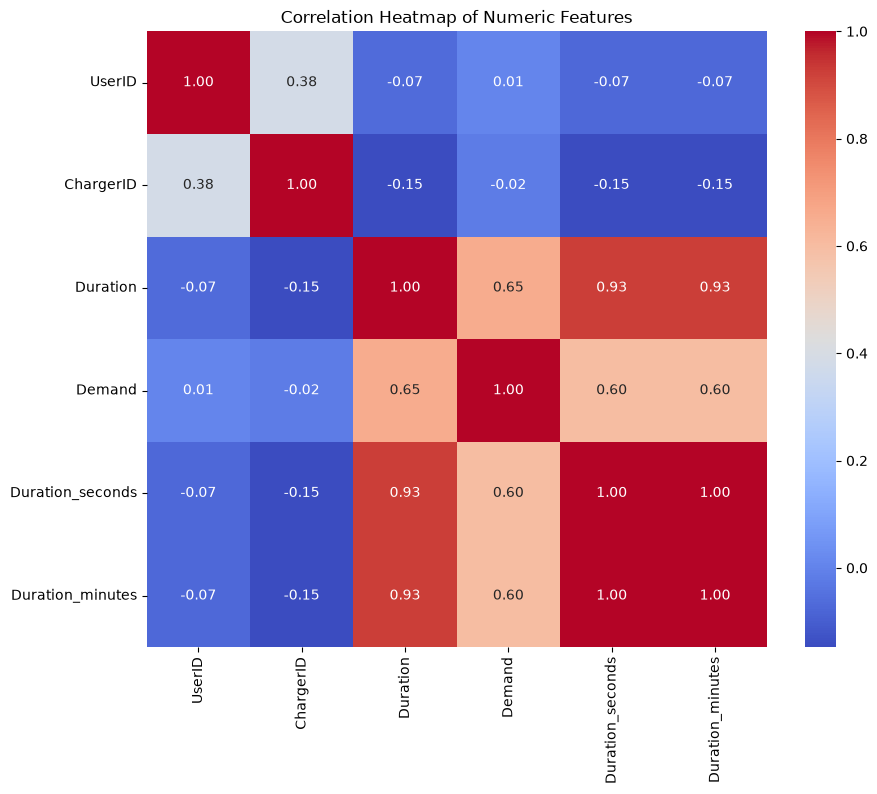

In [211]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Numeric Features")
plt.show()

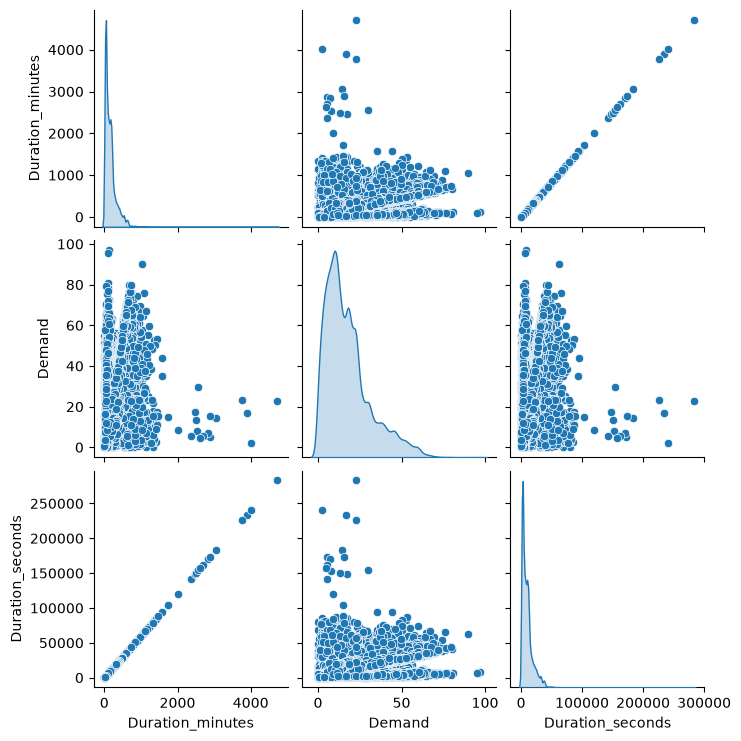

In [212]:
sns.pairplot(df_cleaned[['Duration_minutes','Demand','Duration_seconds']], diag_kind='kde')
plt.show()

In [213]:
# Rank features by correlation with Demand
corr_with_demand = corr_matrix['Demand'].sort_values(ascending=False)
print(corr_with_demand)

Demand              1.000000
Duration            0.654899
Duration_seconds    0.600224
Duration_minutes    0.600211
UserID              0.005818
ChargerID          -0.019052
Name: Demand, dtype: float64


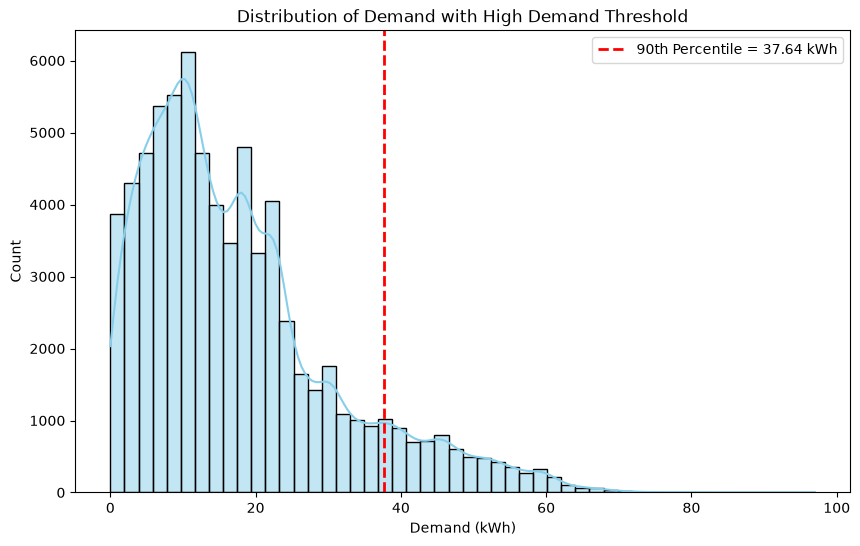

In [214]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate 90th percentile threshold
threshold = df_cleaned['Demand'].quantile(0.90)

# Plot histogram of Demand
plt.figure(figsize=(10,6))
sns.histplot(df_cleaned['Demand'], bins=50, kde=True, color="skyblue")

# Add vertical line for threshold
plt.axvline(threshold, color='red', linestyle='--', linewidth=2, label=f'90th Percentile = {threshold:.2f} kWh')

plt.xlabel("Demand (kWh)")
plt.ylabel("Count")
plt.title("Distribution of Demand with High Demand Threshold")
plt.legend()
plt.show()

### 📊 Exploratory Data Analysis (EDA)

#### Below are the features identified to be added as part of EDA
#### 1. Time-Based Features
- `StartDay`, `EndDay`, `year`, `day_of_week`, `is_weekend`  
- `StartMonth`, `EndMonth`, `time_of_day`  
#### 2. Duration Features
- `Duration_hours`, `is_anomaly`
#### 3. Demand & Efficiency
- `Demand`, `HighDemand`  
#### 4. User Behavior
- `prev_sessions`  

## Feature Engineering

In [ ]:
# Converting minutes to hours (keep precision)
df_cleaned['Duration_hours'] = df_cleaned['Duration_minutes'] / 60

# Rounding values
df_cleaned['Duration_hours'] = df_cleaned['Duration_hours'].round(2)

# flaging anomalies
df_cleaned['is_anomaly'] = (
    (df_cleaned['Duration_minutes'] > 1440)
).astype(int)

def feature_engineering(df):
    """
    Performing feature engineering on EV charging dataset.
    Input: df_cleaned (already cleaned dataset)
    Output: df with engineered features (no rows dropped)
    """

    # --- Time-based features ---
    df['start day'] = df['StartDatetime'].dt.day
    df['start month'] = df['StartDatetime'].dt.month
    df['end day'] = df['EndDatetime'].dt.day
    df['end month'] = df['EndDatetime'].dt.month
    df['year'] = df['StartDatetime'].dt.year
    df['day_of_week'] = df['StartDatetime'].dt.dayofweek  # 0=Monday
    df['is_weekend'] = df['day_of_week'].isin([5,6]).astype(int)
    df['time_of_day'] = pd.cut(df['StartDatetime'].dt.hour,
                               bins=[0,6,12,18,24],
                               labels=['Night','Morning','Afternoon','Evening'],
                               right=False)

    
    # --- Historical usage features ---
    df['prev_sessions'] = df.groupby('ChargerID').cumcount()

    #Classification features
    threshold = df['Demand'].median()
    df['HighDemand'] = (df['Demand'] >= threshold).astype(int)

    return df

df_features = feature_engineering(df_cleaned)
print(df_features.head())
print("---------------------------------------------------\n")
print(f" === Final Shape after adding features ===\n{df_features.shape}")


   UserID  ChargerID ChargerCompany Location ChargerType    StartDay  \
0       0          1              1    hotel           0  2022-09-15   
1       0          1              1    hotel           0  2022-09-14   
2       0          1              1    hotel           0  2022-09-14   
3       0          1              1    hotel           0  2022-09-29   
4       0          1              1    hotel           0  2022-09-25   

  StartTime      EndDay   EndTime       StartDatetime  ... start day  \
0  20:54:02  2022-09-15  23:59:13 2022-09-15 20:54:00  ...        15   
1  20:01:05  2022-09-14  21:31:04 2022-09-14 20:01:00  ...        14   
2  18:54:30  2022-09-14  19:54:29 2022-09-14 18:54:00  ...        14   
3  18:32:51  2022-09-30  00:16:42 2022-09-29 18:32:00  ...        29   
4  19:30:15  2022-09-26  00:30:14 2022-09-25 19:30:00  ...        25   

   start month  end day  end month  year  day_of_week  is_weekend  \
0            9       15          9  2022            3           0

In [224]:
df_features.columns

Index(['UserID', 'ChargerID', 'ChargerCompany', 'Location', 'ChargerType',
       'StartDay', 'StartTime', 'EndDay', 'EndTime', 'StartDatetime',
       'EndDatetime', 'Duration', 'Demand', 'Duration_seconds',
       'Duration_minutes', 'Duration_hours', 'is_anomaly', 'start day',
       'start month', 'end day', 'end month', 'year', 'day_of_week',
       'is_weekend', 'time_of_day', 'prev_sessions', 'HighDemand'],
      dtype='str')

In [225]:
df_features.dtypes

UserID                       int64
ChargerID                    int64
ChargerCompany            category
Location                  category
ChargerType               category
StartDay                    object
StartTime                   object
EndDay                      object
EndTime                     object
StartDatetime       datetime64[us]
EndDatetime         datetime64[us]
Duration                     int64
Demand                     float64
Duration_seconds             int64
Duration_minutes             int64
Duration_hours             float64
is_anomaly                   int64
start day                    int32
start month                  int32
end day                      int32
end month                    int32
year                         int32
day_of_week                  int32
is_weekend                   int64
time_of_day               category
prev_sessions                int64
HighDemand                   int64
dtype: object

In [226]:
df_features = df_features.to_csv(r"D:\Aswini\EDA\EV_charging\evcharging\Data\EVChargingRecords_Features.csv")